# Beneath the Sand: data pipeline
*NASA Space Apps 2026, "Dancing with the SARs" (Egypt)*

This notebook explains **what data we use**, **how we preprocess it**, and **what the final formats are**.

## 1. Goal and why L-band radar
Near the Egypt-Sudan border (Bir Safsaf region, ~22.5-23.1 N, 29.2-31.1 E) ancient rivers lie under a thin layer of very dry sand.
Sunlight reflects off the surface, so photos show flat desert. **L-band radar (24 cm wavelength) goes 1-2 m into hyper-dry sand** and bounces off the
buried gravel and bedrock, so old river channels show up as dark, winding lines. The Space Shuttle radar SIR-A first showed these "radar rivers" in 1981, and
field teams later found Acheulean stone tools in the channel sediments.

We use new **NISAR** L-band data, trace candidate channels automatically, cut the radar into small **patches** that people tag
(`channel` / `site_feature` / `nothing` / `unsure`), and use the tags to train a U-Net.

**Data mode.** By default (`SAMPLE = True`) the notebook runs on a small subset in `notebooks/sample_data/` (~11 MB: one 20 x 20 km radar crop,
the matching optical crop, 9 patches, the patch index and the DB schema), so it can be shared and run without the full dataset.
Set `SAMPLE = False` to run on the full local data (10 radar tiles, 461 patches). `notebooks/make_sample.py` rebuilds the subset.

In [1]:
import os, sys, glob, json
from pathlib import Path

SAMPLE = True        # True: small shareable subset in notebooks/sample_data; False: full repo data

# work from the repo root (the folder that contains notebooks/)
root = Path.cwd()
while not (root / 'notebooks').is_dir() and root != root.parent:
    root = root.parent
os.chdir(root)

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from skimage.filters import sato
from pyproj import Transformer
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 9})

S = Path(os.environ.get('SAMPLE_DIR', 'notebooks/sample_data'))   # e.g. SAMPLE_DIR=notebooks/sample_small for the tiny sample
if SAMPLE:
    sys.path.insert(0, str(S))                       # bundled copy of pipeline/trace_channels.py
    TILE, OPTICAL = S / 'safsaf_crop.npz', S / 'optical_crop.npy'
    PATCH_NPZ_DIR = PATCH_PNG_DIR = S / 'patches'
    INDEX, SCHEMA = S / 'index.json', S / 'schema.prisma'
else:
    sys.path.insert(0, 'pipeline')
    TILE, OPTICAL = Path('data/safsaf/20261017.npz'), Path('data/safsaf/optical.npy')
    PATCH_NPZ_DIR, PATCH_PNG_DIR = Path('data/patches'), Path('web_assets/patches')
    INDEX, SCHEMA = Path('web_assets/patches/index.json'), Path('api/prisma/schema.prisma')
from trace_channels import load, ridge_mask, valleys, trace_tile
%matplotlib inline
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)   # skimage deprecation notices from the pipeline code

db = lambda a: 10 * np.log10(np.clip(np.nan_to_num(a), 1e-6, None))   # linear power -> decibels
print('repo root:', Path.cwd(), '| mode:', 'sample subset' if SAMPLE else 'full data')
print('radar tile:', TILE, f'({TILE.stat().st_size / 1e6:.1f} MB)')

repo root: /home/omar/projects/nasa | mode: sample subset
radar tile: notebooks/sample_data/safsaf_crop.npz (5.8 MB)


## 2. Data sources

| | NISAR L2 GCOV | Sentinel-2 L2A |
|---|---|---|
| **What** | Geocoded polarimetric COVariance: radar backscatter, dual-pol **HHHH** and **HVHV** (linear power, float32) | Surface reflectance, red/green/blue bands |
| **Used for** | Everything: channel tracing, patches, tagging, ML input | Visual comparison only ("the photo shows nothing") |
| **Collection** | `NISAR_L2_GCOV_PROVISIONAL_V1` (ASF DAAC), track 079 descending, frame 077 | `sentinel-2-l2a`, Element84 earth-search STAC, cloud cover < 3 %, newest clear scene |
| **Date** | 2026-10-17 (single acquisition) | most recent clear scene at fetch time |
| **Resolution** | frequencyA grid, 20 m posting | 10 m, averaged onto the 40 m radar grid |
| **CRS** | UTM zone 36N, EPSG:32636 | reprojected to EPSG:32636 |
| **Access** | `pipeline/crop_gcov.py`: earthaccess + h5py stream only a crop of the ~1.6 GB granule (~23 MB per 40 x 40 km crop) | `pipeline/optical.py`: rasterio reads only the needed COG pixels |
| **License** | NASA open data (provisional product) | Copernicus open data (free, attribution) |

**Local files**

* Raw radar crops: `data/safsaf*/20261017.npz` (4) and `data/tiles/*/20261017.npz` (6) = 10 tiles of 2000 x 2000 px (40 x 40 km).
  Keys: `HH`, `HV` (float32 linear power), `x`, `y` (UTM pixel-centre coordinates, m), `epsg`. Dates without HV (single-pol) are skipped at download.
* Optical: `data/safsaf/optical.npy` (uint16 R,G,B reflectance x 10000 on the 40 m radar grid). Raw bands are used because the ready-made true-colour image (TCI) saturates over bright desert.

## 3. Inspect one raw radar crop

In [2]:
T = np.load(TILE)
for k in T.files:
    a = T[k]
    print(f'{k:5s} shape={str(a.shape):13s} dtype={str(a.dtype):8s}', '' if a.ndim == 0 else f'min={a.min():.4g} max={a.max():.4g}', a if a.ndim == 0 else '')
x, y, epsg = T['x'], T['y'], int(T['epsg'])
print(f'\npixel spacing: dx={x[1]-x[0]:.0f} m, dy={y[1]-y[0]:.0f} m (y runs north -> south)')
print(f'extent: {(x[-1]-x[0]+20)/1000:.1f} x {(y[0]-y[-1]+20)/1000:.1f} km')
tf = Transformer.from_crs(epsg, 4326, always_xy=True)
lon0, lat0 = tf.transform(x[0], y[0]); lon1, lat1 = tf.transform(x[-1], y[-1])
print(f'corners (lon, lat): NW ({lon0:.3f}, {lat0:.3f})  SE ({lon1:.3f}, {lat1:.3f})')
print(f'valid (HH > 0) pixels: {(T["HH"] > 0).mean()*100:.1f} %')

HH    shape=(1000, 1000)  dtype=float32  min=0.0009814 max=1.452 
HV    shape=(1000, 1000)  dtype=float32  min=0.0003158 max=0.06146 
x     shape=(1000,)       dtype=float64  min=1.088e+05 max=1.288e+05 
y     shape=(1000,)       dtype=float64  min=2.493e+06 max=2.513e+06 
epsg  shape=()            dtype=int64     32636

pixel spacing: dx=20 m, dy=-20 m (y runs north -> south)
extent: 20.0 x 20.0 km
corners (lon, lat): NW (29.194, 22.682)  SE (29.392, 22.507)
valid (HH > 0) pixels: 100.0 %


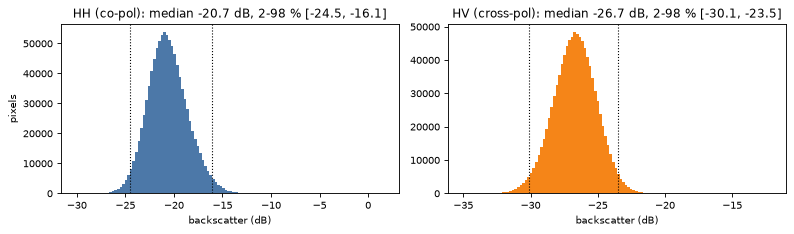

In [3]:
HH, HV = db(T['HH']), db(T['HV'])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, d, name, c in [(ax[0], HH, 'HH (co-pol)', '#4c78a8'), (ax[1], HV, 'HV (cross-pol)', '#f58518')]:
    v = d[d > -50]
    a.hist(v.ravel(), bins=120, color=c)
    p2, p50, p98 = np.percentile(v, [2, 50, 98])
    for p in (p2, p98): a.axvline(p, color='k', ls=':', lw=1)
    a.set_title(f'{name}: median {p50:.1f} dB, 2-98 % [{p2:.1f}, {p98:.1f}]'); a.set_xlabel('backscatter (dB)')
ax[0].set_ylabel('pixels'); plt.tight_layout(); plt.show()

HV is ~6-8 dB darker than HH (cross-pol returns are weaker). Smooth sand and buried channel fill are dark; rough rock is bright.

## 4. Radar vs optical: the channels are invisible in the photo

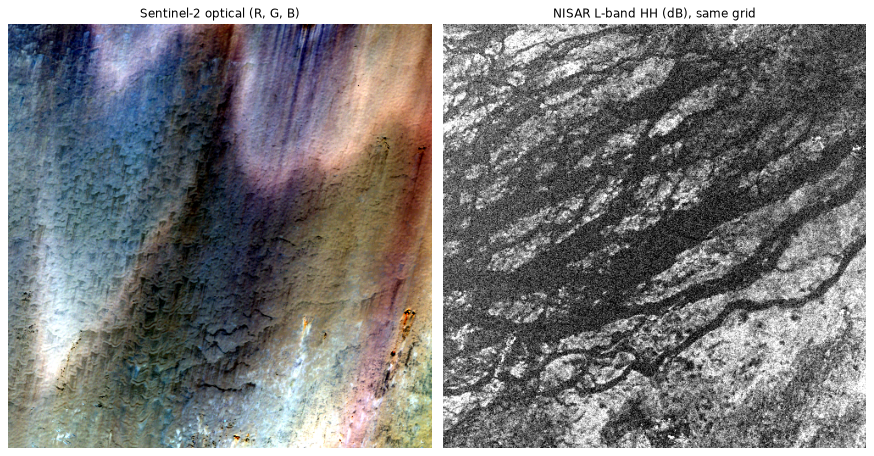

optical array: (3, 500, 500) | radar 40 m array: (500, 500)


In [4]:
opt = np.load(OPTICAL).astype(float)                       # (3, rows, cols) at 40 m
rgb = np.dstack([np.clip((b - np.percentile(b, 1)) / (np.percentile(b, 99) - np.percentile(b, 1)), 0, 1) for b in opt])  # 1-99 % stretch per band
hh40, valid40, *_ = load(TILE)                              # radar at 40 m, dB
lo, hi = np.percentile(hh40[valid40], [2, 98])
fig, ax = plt.subplots(1, 2, figsize=(11, 5.6))
ax[0].imshow(rgb); ax[0].set_title('Sentinel-2 optical (R, G, B)')
ax[1].imshow(hh40, cmap='gray', vmin=lo, vmax=hi); ax[1].set_title('NISAR L-band HH (dB), same grid')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
print('optical array:', opt.shape, '| radar 40 m array:', hh40.shape)

The photo shows surface sand: dune ripples and colour changes in the sand, but no river network. The radar sees through that layer and shows a branching network of dark, winding channels: the buried river system.

## 5. Preprocessing, step by step
All steps come from `pipeline/trace_channels.py` (`load`, `ridge_mask`, `valleys`, `trace_tile`):

1. **Linear -> dB** after **2 x 2 intensity averaging** (20 m -> 40 m working resolution; averaging in linear power, then `10*log10`).
2. **Speckle filter**: 5 x 5 median filter.
3. **Background removal**: subtract a Gaussian blur (sigma = 30 px = 1.2 km) to remove km-scale brightness trends.
4. **Ridge filter**: Sato filter for *dark* line-like features (sigmas 3, 5, 8 px), then rough rocky areas (high local std or very bright) are masked out, because the dark gaps between rock blocks also look like lines.
5. Keep the top 10 % of the ridge response -> clean up -> **skeletonize** -> keep only connected networks >= 100 px (4 km) -> polylines.
6. **Wide valleys**: heavily smoothed image, darkest 22 %, regions >= ~5 km2 and elongated (axis ratio >= 2.5).

Below, steps 2-4 are re-computed in-line (same parameters) so the intermediate images can be shown; the final result uses `trace_tile`.

*Sample mode note:* thresholds are percentiles of the whole tile, so the tracer gives somewhat different results on a 20 km crop than on the full 40 km tile
(on the crop alone no wide valley passes the filters). Panel 6 therefore shows the masks computed on the **full tile** (stored in
`sample_data/tracer_fulltile.npz`), which are exactly what the patches contain.

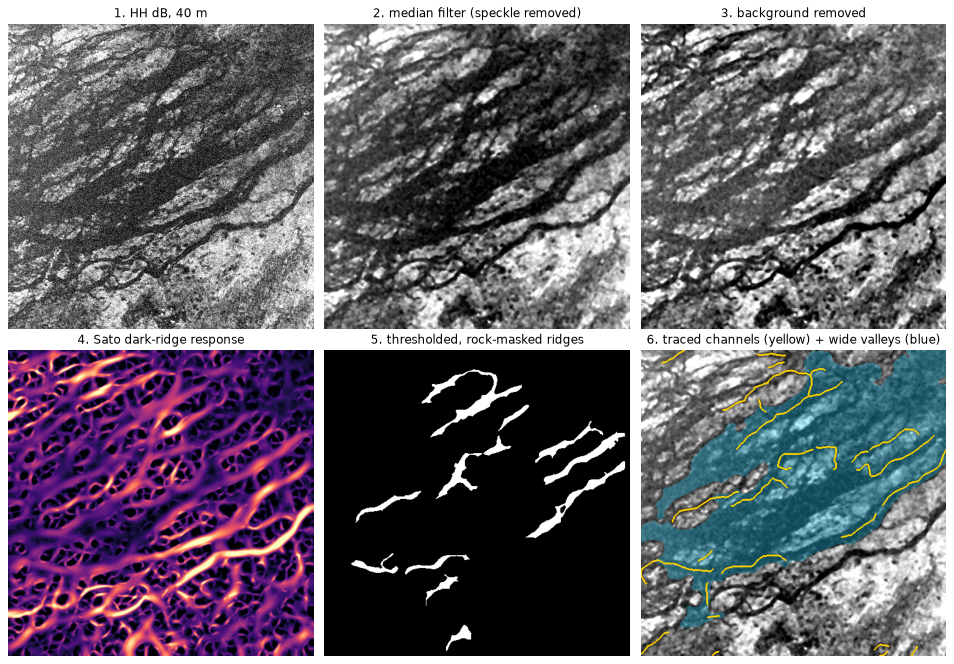

tracer on this array: 23 channel segments, 53 km, 0 valley polygons
panel 6 (full-tile run, cropped): line pixels 0.72 %, valley pixels 44.2 %


In [5]:
fill = np.where(valid40, hh40, np.median(hh40[valid40]))
sm = ndi.median_filter(fill, 5)                          # 2. speckle filter
flat = sm - ndi.gaussian_filter(sm, 30)                  # 3. background removal
ridge = sato(flat, sigmas=[3, 5, 8], black_ridges=True)  # 4. dark-ridge response
mask, _ = ridge_mask(hh40, valid40)                      # 4-5. with rough-rock masking + threshold
R = trace_tile(str(TILE))                                # tracer on this array
if SAMPLE:
    F = np.load(S / 'tracer_fulltile.npz'); line_m, valley_m = F['line_mask'], F['valley_mask']   # full-tile run, cropped
else:
    line_m, valley_m = R['line_mask'], R['valley_mask']

st = lambda a: dict(vmin=np.percentile(a, 2), vmax=np.percentile(a, 98))
fig, ax = plt.subplots(2, 3, figsize=(12, 8.4))
ax = ax.ravel()
ax[0].imshow(hh40, cmap='gray', **st(hh40)); ax[0].set_title('1. HH dB, 40 m')
ax[1].imshow(sm, cmap='gray', **st(sm)); ax[1].set_title('2. median filter (speckle removed)')
ax[2].imshow(flat, cmap='gray', **st(flat)); ax[2].set_title('3. background removed')
ax[3].imshow(ridge, cmap='magma', vmin=0, vmax=np.percentile(ridge, 99)); ax[3].set_title('4. Sato dark-ridge response')
ax[4].imshow(mask, cmap='gray'); ax[4].set_title('5. thresholded, rock-masked ridges')
ax[5].imshow(R['sm'], cmap='gray', **st(R['sm']))
ov = np.zeros(line_m.shape + (4,)); ov[valley_m.astype(bool)] = (0.18, 0.83, 1, 0.35)
ov[ndi.binary_dilation(line_m.astype(bool))] = (1, 0.83, 0, 1)
ax[5].imshow(ov); ax[5].set_title('6. traced channels (yellow) + wide valleys (blue)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
km = sum(np.hypot(*np.diff(l, axis=0).T).sum() for l in R['lines']) * 0.04
print(f"tracer on this array: {len(R['lines'])} channel segments, {km:.0f} km, {len(R['valleys'])} valley polygons")
print(f"panel 6 ({'full-tile run, cropped' if SAMPLE else 'this run'}): line pixels {line_m.mean()*100:.2f} %, valley pixels {valley_m.mean()*100:.1f} %")

## 6. Patch grid
`pipeline/make_patches.py` cuts every tile on a **fixed UTM grid** into **256 x 256 px patches at 20 m (5.12 x 5.12 km)**.
Patch id = `<epsg>_<grid col>_<grid row>`, so overlapping tiles never create duplicates. Patches with < 98 % valid pixels are dropped.
The tracer masks (40 m) are upsampled back to 20 m and stored with each patch.

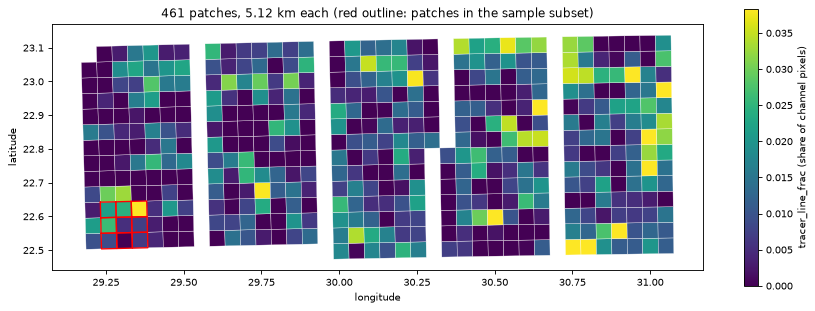

patches: 461 | area: 12,085 km2 | lon 29.17-31.08, lat 22.47-23.14
patches with traced channels (line_frac > 0.002): 323 | with valleys (valley_frac > 0): 116
tracer_line_frac: median 0.0079, max 0.0557 | tracer_valley_frac: median 0.0000, max 1.0000
patches per source tile: {'safsaf': 49, 'safsaf_e': 42, 'safsaf_n': 41, 'safsaf_ne': 49, 't_30.13_22.65': 42, 't_30.13_22.97': 49, 't_30.52_22.65': 49, 't_30.52_22.97': 42, 't_30.91_22.65': 49, 't_30.91_22.97': 49}


In [6]:
index = json.load(open(INDEX))
here = {p.stem for p in PATCH_NPZ_DIR.glob('*.npz')}
lf = np.array([p['tracer_line_frac'] for p in index]); vf = np.array([p['tracer_valley_frac'] for p in index])
fig, ax = plt.subplots(figsize=(11, 4.6))
cmap = plt.get_cmap('viridis'); norm = plt.Normalize(0, np.percentile(lf, 98))
for p, v in zip(index, lf):
    c = np.array(p['corners'] + [p['corners'][0]])
    ax.fill(c[:, 0], c[:, 1], color=cmap(norm(v)), ec='white', lw=0.3)
    if SAMPLE and p['id'] in here: ax.plot(c[:, 0], c[:, 1], color='red', lw=1.2)
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label='tracer_line_frac (share of channel pixels)', shrink=0.8)
ax.set_aspect(1 / np.cos(np.radians(22.8))); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title(f'{len(index)} patches, 5.12 km each' + (' (red outline: patches in the sample subset)' if SAMPLE else ''))
plt.tight_layout(); plt.show()

tiles = {}
for p in index: tiles[p['tile']] = tiles.get(p['tile'], 0) + 1
lons = [c[0] for p in index for c in p['corners']]; lats = [c[1] for p in index for c in p['corners']]
print(f'patches: {len(index)} | area: {len(index) * 5.12**2:,.0f} km2 | lon {min(lons):.2f}-{max(lons):.2f}, lat {min(lats):.2f}-{max(lats):.2f}')
print(f'patches with traced channels (line_frac > 0.002): {(lf > 0.002).sum()} | with valleys (valley_frac > 0): {(vf > 0).sum()}')
print(f'tracer_line_frac: median {np.median(lf):.4f}, max {lf.max():.4f} | tracer_valley_frac: median {np.median(vf):.4f}, max {vf.max():.4f}')
print('patches per source tile:', tiles)

## 7. Final formats

### 7a. ML file: `data/patches/<id>.npz`

In [7]:
files = sorted(PATCH_NPZ_DIR.glob('*.npz'))
pid = max(files, key=lambda f: np.load(f)['line'].mean()).stem          # the patch with most traced channel
P = np.load(PATCH_NPZ_DIR / f'{pid}.npz')
print('patch', pid, f'({(PATCH_NPZ_DIR / f"{pid}.npz").stat().st_size / 1e3:.0f} kB)')
for k in P.files:
    a = P[k].astype(np.float32)
    print(f'  {k:6s} {str(P[k].dtype):8s} {P[k].shape}  min {a.min():.2f}  max {a.max():.2f}  mean {a.mean():.3f}')
print(f'\n{len(files)} patch files here, {sum(f.stat().st_size for f in files) / 1e6:.1f} MB total')

patch 32636_24_489 (187 kB)
  hh     float16  (256, 256)  min -28.86  max -10.72  mean -21.118
  hv     float16  (256, 256)  min -34.88  max -20.97  mean -27.079
  line   uint8    (256, 256)  min 0.00  max 1.00  mean 0.045
  valley uint8    (256, 256)  min 0.00  max 1.00  mean 0.928

9 patch files here, 1.7 MB total


`hh`, `hv`: backscatter in dB (float16). `line`, `valley`: tracer masks (uint8 0/1), useful as weak labels or a baseline. Crowd tags become the U-Net target.

### 7b. Web images: `web_assets/patches/<id>_{radar,rgb,tracer}.png`
256 x 256 PNGs with **one global contrast stretch** (2-98 % over all tiles) so patches look consistent:
* `_radar.png`: grayscale HH.
* `_rgb.png`: false colour, R = HH, G = HV, B = HH - HV.
* `_tracer.png`: RGBA overlay, valleys in translucent blue, channel lines in opaque light blue.

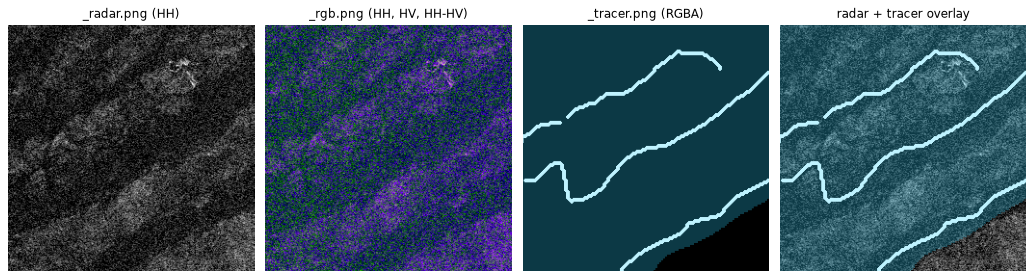

{'radar': ('L', (256, 256)), 'rgb': ('RGB', (256, 256)), 'tracer': ('RGBA', (256, 256))}


In [8]:
ims = {s: Image.open(PATCH_PNG_DIR / f'{pid}_{s}.png') for s in ('radar', 'rgb', 'tracer')}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
ax[0].imshow(ims['radar'], cmap='gray'); ax[0].set_title('_radar.png (HH)')
ax[1].imshow(ims['rgb']); ax[1].set_title('_rgb.png (HH, HV, HH-HV)')
ax[2].imshow(np.zeros((256, 256)), cmap='gray'); ax[2].imshow(ims['tracer']); ax[2].set_title('_tracer.png (RGBA)')
ax[3].imshow(ims['radar'], cmap='gray'); ax[3].imshow(ims['tracer']); ax[3].set_title('radar + tracer overlay')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
print({s: (im.mode, im.size) for s, im in ims.items()})

### 7c. Patch index: `web_assets/patches/index.json`

In [9]:
rec = next(p for p in index if p['id'] == pid)
print(json.dumps(rec, indent=1).replace('\n   ', ' ').replace('\n  ]', ']'))

{
 "id": "32636_24_489",
 "tile": "safsaf",
 "corners": [
  [ 29.33144, 22.644323],
  [ 29.381169, 22.645455],
  [ 29.382379, 22.599294],
  [ 29.332666, 22.598165]
 ],
 "center": [
  29.356913,
  22.621812
 ],
 "tracer_line_frac": 0.0452,
 "tracer_valley_frac": 0.9278
}


`corners` are the patch footprint in lon/lat (NW, NE, SE, SW), `center` is the centre point, and `tile` is the source crop.

### 7d. Database (PostGIS via Prisma)
The index is loaded into PostgreSQL + PostGIS (`api/prisma/schema.prisma`, migration in `api/prisma/migrations/`):

| Table | Purpose | Key columns |
|---|---|---|
| `patches` | one row per patch | `id`, `tile`, `geom` (Polygon 4326), `center` (Point 4326), `tracer_line`, `tracer_valley`, `ai_score` (U-Net probability), `gold_label` (known answer for quizzes) |
| `sessions` | anonymous taggers | `id` (random, kept in browser), `name`, `trust` (0-1, default 0.7), `flagged` (spam/troll) |
| `tags` | one answer per patch per person | `patch_id`, `session_id`, `label` (enum `channel` / `site_feature` / `nothing` / `unsure`), `ms` (time to answer), `is_quiz`, `p_correct` |
| `sites` | known archaeological / reference sites | `name`, `kind`, `age_text`, `confidence` (`published` / `approximate`), `source_url`, `geom` (Point) |
| `consensus` (view) | trust-weighted vote per patch | `votes`, `w_channel`, `w_site`, `w_nothing`, `channel_share` (excludes flagged sessions and quiz answers) |

In [10]:
import re
txt = open(SCHEMA).read()
for name, body in re.findall(r'model (\w+) \{(.*?)\n\}', txt, re.S):
    cols = [l.split()[0] for l in body.strip().splitlines() if l.strip() and not l.strip().startswith(('@@', '//'))]
    table = re.search(r'@@map\("(\w+)"\)', body).group(1)
    print(f'{name:8s} -> {table:9s}: {", ".join(cols)}')

Patch    -> patches  : id, tile, geom, center, tracerLine, tracerValley, aiScore, goldLabel, tags
Session  -> sessions : id, name, trust, flagged, createdAt, tags
Tag      -> tags     : id, patch, patchId, session, sessionId, label, ms, isQuiz, pCorrect, createdAt
Site     -> sites    : id, name, kind, ageText, note, confidence, sourceUrl, geom


## 8. Known limitations
* **Tracer false positives**: rocky outcrops, dune troughs and wind streaks also produce dark lines. Rough-rock masking removes many but not all; the tracer is a hint for taggers and a weak baseline, not ground truth.
* **Single date**: all tiles come from one acquisition (2026-10-17, track 079 descending). No multi-date averaging (which would reduce speckle) and no change detection.
* **Provisional data**: `NISAR_L2_GCOV_PROVISIONAL_V1` is an early product; calibration and geolocation may change in later releases.
* **Optical comparison only for one tile** (`data/safsaf`), and its acquisition date differs from the radar date.
* **Site coordinates unverified**: Bir Safsaf and other archaeological site locations are approximate (`confidence = 'approximate'` in `sites`) until checked against published sources.
* **Penetration depends on dryness**: the 1-2 m L-band penetration assumes hyper-dry sand; deeper or damp fill will not show.